# Лабораторная работа №2: Классификация (Titanic)

**Цель:** пройти полный цикл решения задачи классификации: анализ данных → baseline → сравнение пяти алгоритмов → метрики, ошибки и важность признаков.

**Данные (комплект организатора):**
- `data/train.csv` — 891 пассажир с ответами; признаки `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked`, цель `Survived`, служебный `Id`;
- `data/test.csv` — 1000 объектов **без ответов** (оценивается организатором скрытно);
- `data/sample_submission.csv` — шаблон посылки `Id,Survived`.

`Name`, `Ticket`, `Cabin` и `PassengerId` организатор из данных уже удалил; `Id` нужен только для сопоставления строк и **не должен использоваться как признак**. Основная метрика — **F1 для класса `Survived = 1`**, минимальный порог — **F1 > 0.70**.

**Терминология.** Ответов для `test.csv` у нас нет, поэтому «тестовая выборка» из задания — это **отложенная часть `train.csv`** (hold-out, 20%), которую модели не видят до финальной оценки. Переменные `X_test`, `y_test` в коде — именно она. `test.csv` используется один раз — для формирования посылки в конце.

**Как устроена работа:** 1) первичный анализ; 2) разбиение; 3) анализ признаков; 4) подготовка данных; 5) baseline; 6) пять моделей; 7) честное сравнение; 8) feature importance; 9) анализ ошибок; 10) посылка для `test.csv`; 11) итоги.

**Принципы честности.** Отложенная часть не участвует в подборе гиперпараметров: всё подбирается кросс-валидацией внутри обучающей части (F1, одинаковые фолды для всех моделей). Все преобразования с обучаемыми параметрами находятся внутри `Pipeline` и обучаются только на обучающей части.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold, GridSearchCV,
                                     cross_val_score, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
F1_THRESHOLD = 0.70
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Первичный анализ данных

In [2]:
full = pd.read_csv("data/train.csv")
sub = pd.read_csv("data/test.csv")                    # без ответов, используется только в конце
sample = pd.read_csv("data/sample_submission.csv")
FEATS_RAW = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

print("train:", full.shape, " test.csv:", sub.shape, " sample_submission:", sample.shape)
display(full.head())
full.info()

train: (891, 9)  test.csv: (1000, 8)  sample_submission: (1000, 2)


,Id,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,87482818,3,male,22.0,1,0,7.2500,S,0
1,52187593,1,female,38.0,1,0,71.2833,C,1
2,24292843,3,female,26.0,0,0,7.9250,S,1
3,23247479,1,male,54.0,0,0,51.8625,S,0
4,83808344,3,male,2.0,3,1,21.0750,S,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Id        891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
 8   Survived  891 non-null    int64  
dtypes: float64(2), int64(5), object(2)
memory usage: 62.8+ KB


In [3]:
miss = pd.DataFrame({"train: пропусков": full.isna().sum(), "train, %": (full.isna().mean() * 100).round(1),
                     "test.csv: пропусков": sub.isna().sum().reindex(full.columns), "test.csv, %": (sub.isna().mean() * 100).round(1).reindex(full.columns)})
display(miss[(miss.iloc[:, 0] > 0) | (miss.iloc[:, 2] > 0)])

dup_feat = full.duplicated(FEATS_RAW, keep=False)
dup_full = full.duplicated(FEATS_RAW + ["Survived"], keep=False)
print("Id уникален:", full.Id.is_unique, "| пересечение Id train и test.csv:", len(set(full.Id) & set(sub.Id)))
print(f"Строк, у которых признаки совпадают с другой строкой: {dup_feat.sum()} (групп: {full[dup_feat].groupby(FEATS_RAW, dropna=False).ngroups})")
print(f"  из них совпадают и по целевой: {dup_full.sum()}; противоречивых групп (одинаковые признаки, разные ответы): "
      f"{full[dup_feat].groupby(FEATS_RAW, dropna=False).Survived.nunique().gt(1).sum()}")
print("Дубликатов в test.csv:", sub.duplicated(FEATS_RAW).sum())
seq = (full.Id >= 10_000_000) & (full.Id < 10_001_000)
print(f"\nId: {seq.sum()} строк train имеют последовательные Id 10000000–{full.Id[seq].max()} (остальные — случайные восьмизначные); "
      f"в test.csv таких Id: {((sub.Id >= 10_000_000) & (sub.Id < 10_001_000)).sum()}")
print(f"  доля выживших в этом блоке: {full.Survived[seq].mean():.3f}, в остальных: {full.Survived[~seq].mean():.3f}; корреляция Id и Survived: {full[['Id', 'Survived']].corr().iloc[0, 1]:.3f}")
m = sub[FEATS_RAW].merge(full[FEATS_RAW].drop_duplicates(), how="left", indicator=True)
print(f"Доля объектов test.csv, у которых вектор признаков точно совпадает с train: {(m._merge == 'both').mean():.3f}")

print("\nРаспределение целевой переменной:")
display(pd.DataFrame({"n": full.Survived.value_counts(), "доля": full.Survived.value_counts(normalize=True).round(3)}))

cmp = pd.concat({"train": full[FEATS_RAW].describe().T[["mean", "std", "min", "50%", "max"]],
                 "test.csv": sub[FEATS_RAW].describe().T[["mean", "std", "min", "50%", "max"]]}, axis=1)
display(cmp.round(2))
for c in ["Sex", "Pclass", "Embarked"]:
    display(pd.DataFrame({"train": full[c].value_counts(normalize=True), "test.csv": sub[c].value_counts(normalize=True)}).round(3).T)

,train: пропусков,"train, %",test.csv: пропусков,"test.csv, %"
Age,177,19.9,161.0,16.1
Embarked,2,0.2,0.0,0.0


Id уникален: True | пересечение Id train и test.csv: 0
Строк, у которых признаки совпадают с другой строкой: 193 (групп: 66)
  из них совпадают и по целевой: 167; противоречивых групп (одинаковые признаки, разные ответы): 16
Дубликатов в test.csv: 0

Id: 267 строк train имеют последовательные Id 10000000–10000266 (остальные — случайные восьмизначные); в test.csv таких Id: 0
  доля выживших в этом блоке: 0.382, в остальных: 0.385; корреляция Id и Survived: -0.020
Доля объектов test.csv, у которых вектор признаков точно совпадает с train: 0.000

Распределение целевой переменной:


,n,доля
Survived,,
0,549,0.616
1,342,0.384


train                             test.csv                           
         mean    std   min    50%     max     mean    std   min   50%     max
Pclass   2.31   0.84  1.00   3.00    3.00     2.31   0.85  1.00   3.0    3.00
Age     29.70  14.53  0.42  28.00   80.00    29.42  14.23  0.75  28.0   72.00
SibSp    0.52   1.10  0.00   0.00    8.00     0.60   1.21  0.00   0.0    8.00
Parch    0.38   0.81  0.00   0.00    6.00     0.40   0.80  0.00   0.0    6.00
Fare    32.20  49.69  0.00  14.45  512.33    31.95  45.79  0.00  16.1  486.81

Sex,male,female
train,0.648,0.352
test.csv,0.656,0.344


Pclass,3,1,2
train,0.551,0.242,0.207
test.csv,0.562,0.255,0.183


Embarked,S,C,Q
train,0.724,0.189,0.087
test.csv,0.711,0.191,0.098


**Краткие выводы по структуре данных**

- `train.csv`: 891 объект, 7 признаков + цель + служебный `Id`. Типы: `Pclass` — порядковый (1–3), `Sex`, `Embarked` — категориальные, `Age`, `Fare` — непрерывные, `SibSp`, `Parch` — счётчики (хвост до 8 и 6). `Name`, `Ticket`, `Cabin` организатор уже удалил.
- **Пропуски:** `Age` — 177 (19.9%; в `test.csv` 16.1%), `Embarked` — 2 (0.2%; в `test.csv` пропусков нет). Остальные признаки заполнены.
- **Дубликаты:** 193 строки (66 групп) совпадают с другой строкой по всем признакам (семьи и группы, у которых одинаковые класс, плата, порт, число родственников). В 16 группах при **одинаковых признаках ответы разные** — это неустранимый шум: никакая модель не отделит такие объекты. Это важно для разбиения (раздел 2).
- **Баланс классов:** 61.6% погибших / 38.4% выживших. Модель «все погибли» получит accuracy ≈ 0.6, ничего не предсказывая, поэтому основная метрика — F1 по классу 1.
- **`Id`:** уникален и с `test.csv` не пересекается, но устроен неслучайно: 267 строк train имеют последовательные Id `10000000–10000266`, остальные — случайные восьмизначные числа, а в `test.csv` последовательных Id нет. Это признак происхождения строки (пакета), а не пассажира; связи с исходом нет (корреляция −0.02, выживаемость 38.2% против 38.5%). По условию `Id` — не признак, используем только для посылки.
- **`test.csv` и train:** маргинальные распределения почти совпадают (65.6% мужчин против 64.8%; доли классов, средние `Age` и `Fare`), внутри `test.csv` дубликатов нет, а точных совпадений вектора признаков с train — **0%**. То есть запомнить объекты из train для предсказания `test.csv` нельзя: нужна именно обобщающая способность.
- **Признаки, требующие внимания:** `Age` (пропуски, 20%), `Fare` (тяжёлый хвост до 512, есть нули), `Embarked` (2 пропуска), `Id` (запрещён и неинформативен), а также почти уникальные `Age` и `Fare`, по которым дерево теоретически может «запоминать» отдельных пассажиров (проверим в разделе 9).

## 2. Разбиение на обучающую и отложенную части

В train 193 строки (66 групп) имеют «двойников» с идентичным набором признаков (у пассажиров из одной семьи и группы совпадают класс, плата, порт, число родственников). При обычном случайном делении двойник попадает и в обучение, и в отложенную часть, и модель может «угадать» ответ по памяти. В `test.csv` точных совпадений с train **нет вообще** (раздел 1), то есть запоминание там не поможет. Чтобы наша оценка была честной и сопоставимой с итоговой, делим данные **с группировкой по вектору признаков**: идентичные строки всегда остаются по одну сторону разбиения.

Разбиение — `StratifiedGroupKFold` (1 из 5 фолдов ≈ 20% — hold-out), `random_state = 42`: сохраняется доля классов и целостность групп. Доля классов сохраняется приблизительно (группы целиком уходят в одну часть, поэтому 0.378 в обучающей части против 0.406 в hold-out при 0.384 в целом — неизбежная цена группировки). Оно **единое** для всех моделей. Внутри обучающей части кросс-валидация тоже групповая и стратифицированная.

In [4]:
X = full.drop(columns="Survived")
y = full["Survived"]
key = full[FEATS_RAW].astype(str).agg("|".join, axis=1)
groups_all = pd.factorize(key)[0]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr_idx, ho_idx = next(sgkf.split(X, y, groups_all))
X_train, X_test = X.iloc[tr_idx], X.iloc[ho_idx]
y_train, y_test = y.iloc[tr_idx], y.iloc[ho_idx]
g_train = groups_all[tr_idx]

print("train-часть:", X_train.shape, " hold-out:", X_test.shape)
print("Доля выживших: train-часть = %.3f, hold-out = %.3f, весь train.csv = %.3f" % (y_train.mean(), y_test.mean(), y.mean()))
print("Объектов hold-out с двойником в train-части:", int(key.iloc[ho_idx].isin(set(key.iloc[tr_idx])).sum()))

# для сравнения: обычное случайное стратифицированное разбиение
nv_tr, nv_te = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("При обычном случайном разбиении двойник в обучении имели бы %.1f%% объектов отложенной части"
      % (100 * key.iloc[nv_te].isin(set(key.iloc[nv_tr])).mean()))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # одни и те же фолды для всех моделей

train-часть: (711, 8)  hold-out: (180, 8)
Доля выживших: train-часть = 0.378, hold-out = 0.406, весь train.csv = 0.384
Объектов hold-out с двойником в train-части: 0
При обычном случайном разбиении двойник в обучении имели бы 20.1% объектов отложенной части


## 3. Анализ признаков и связи с целевой переменной (только обучающая часть)

Производные признаки — фиксированные правила для каждой строки (ничего не обучается по данным), поэтому утечки не создают:
- `FamilySize = SibSp + Parch + 1`;
- `Fare_log = log(1 + Fare)` — у `Fare` сильный правый хвост (важно для SVM/KNN).

In [5]:
def add_features(d):
    d = d.copy()
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["Fare_log"] = np.log1p(d["Fare"])
    return d


X_train, X_test = add_features(X_train), add_features(X_test)
tr = X_train.assign(Survived=y_train)

for col in ["Sex", "Pclass", "Embarked"]:
    display(tr.groupby(col, dropna=False).Survived.agg(n="count", survival_rate="mean").round(3).T)
fam = pd.cut(tr.FamilySize, [0, 1, 2, 4, 20], labels=["1", "2", "3-4", "5+"])
display(tr.groupby(fam).Survived.agg(n="count", survival_rate="mean").round(3).T)
agegrp = pd.cut(tr.Age, [0, 12, 18, 35, 60, 100])
display(tr.groupby(agegrp).Survived.agg(n="count", survival_rate="mean").round(3).T)

print("Age пропущен: выживаемость %.3f vs %.3f у остальных" % (
    tr[tr.Age.isna()].Survived.mean(), tr[tr.Age.notna()].Survived.mean()))
print("Доля пропусков Age по Pclass:")
display(tr.groupby("Pclass").Age.apply(lambda s: s.isna().mean()).round(3).to_frame("доля NaN").T)
print("Средняя плата по классам:")
display(tr.groupby("Pclass").Fare.agg(["mean", "median"]).round(1).T)

Sex,female,male
n,248.000,463.000
survival_rate,0.738,0.186


Pclass,1,2,3
n,177.00,153.000,381.000
survival_rate,0.61,0.471,0.234


Embarked,C,Q,S,NaN
n,134.000,48.000,528.000,1.0
survival_rate,0.515,0.417,0.339,1.0


FamilySize,1,2,3-4,5+
n,424.000,131.000,105.00,51.000
survival_rate,0.302,0.534,0.61,0.137


Age,"(0, 12]","(12, 18]","(18, 35]","(35, 60]","(60, 100]"
n,58.000,55.000,287.00,160.000,16.000
survival_rate,0.517,0.491,0.38,0.406,0.125


Age пропущен: выживаемость 0.267 vs 0.405 у остальных
Доля пропусков Age по Pclass:


Pclass,1,2,3
доля NaN,0.13,0.059,0.27


Средняя плата по классам:


Pclass,1,2,3
mean,79.6,19.8,13.4
median,58.0,14.5,8.0


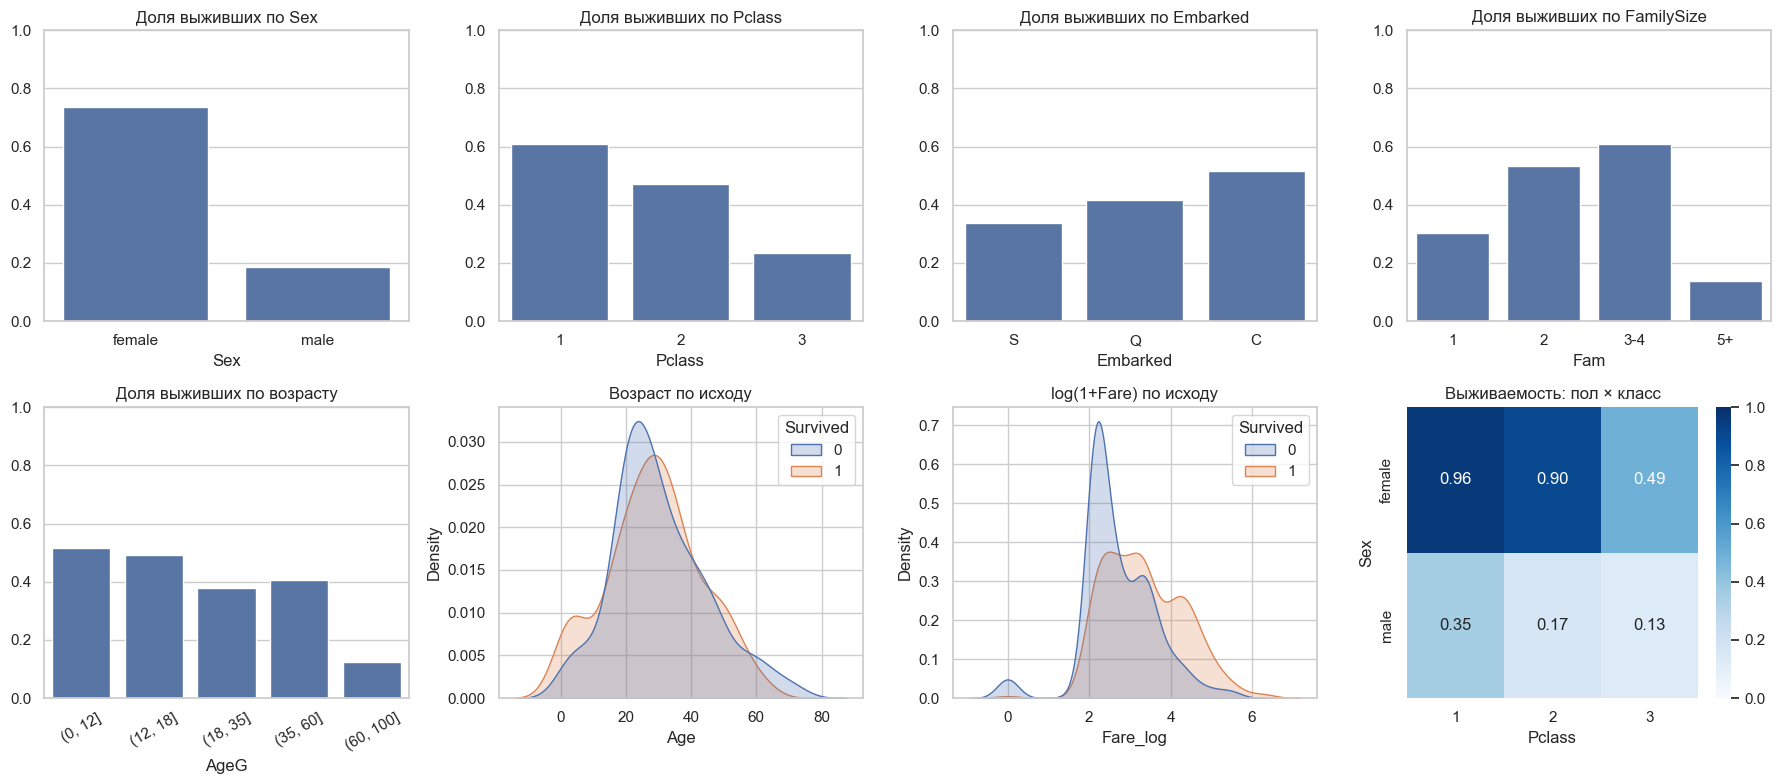

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=tr, x=col, y="Survived", errorbar=None, ax=ax, color="#4c72b0")
    ax.set_title(f"Доля выживших по {col}"); ax.set_ylim(0, 1); ax.set_ylabel("")
sns.barplot(data=tr.assign(Fam=fam), x="Fam", y="Survived", errorbar=None, ax=axes[0, 3], color="#4c72b0")
axes[0, 3].set_title("Доля выживших по FamilySize"); axes[0, 3].set_ylim(0, 1); axes[0, 3].set_ylabel("")
sns.barplot(data=tr.assign(AgeG=agegrp.astype(str)), x="AgeG", y="Survived", errorbar=None, ax=axes[1, 0], color="#4c72b0",
            order=[str(c) for c in agegrp.cat.categories])
axes[1, 0].set_title("Доля выживших по возрасту"); axes[1, 0].set_ylim(0, 1); axes[1, 0].set_ylabel(""); axes[1, 0].tick_params(axis="x", rotation=30)
sns.kdeplot(data=tr, x="Age", hue="Survived", common_norm=False, fill=True, ax=axes[1, 1]); axes[1, 1].set_title("Возраст по исходу")
sns.kdeplot(data=tr, x="Fare_log", hue="Survived", common_norm=False, fill=True, ax=axes[1, 2]); axes[1, 2].set_title("log(1+Fare) по исходу")
sns.heatmap(tr.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean"),
            annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1, 3]); axes[1, 3].set_title("Выживаемость: пол × класс")
plt.tight_layout(); plt.show()

**Краткие выводы по связи признаков с целевой переменной (обучающая часть)**

1. **Пол — главный сигнал:** выжили 73.8% женщин и 18.6% мужчин. Класс: 61.0% / 47.1% / 23.4% для 1/2/3 класса.
2. **Пол и класс взаимодействуют** (тепловая карта): женщины 1 и 2 классов выживали в 96% и 90% случаев, женщины 3 класса — лишь в 49%; мужчины по классам — 35% / 17% / 13%. То есть простое «женщина → выжила» не работает для 3 класса, а «мужчина → погиб» — для мужчин 1 класса. Такие смешанные группы дадут основную долю ошибок.
3. **Возраст:** дети до 18 лет выживали чаще (51.7% и 49.1%), 18–60 — около 38–41%, старше 60 — 12.5% (мало наблюдений: 16). Пропуск `Age` информативен: 26.7% выживших у пассажиров без возраста против 40.5% у остальных. Пропуски сконцентрированы в 3 классе (27% против 13% и 6%), но дело не только в классе: и внутри классов выживаемость без возраста ниже (1 класс — 0.48 против 0.63, 2 класс — 0.22 против 0.49, 3 класс — 0.22 против 0.24), поэтому индикатор пропуска добавляем.
4. **Размер семьи — нелинейный признак:** одиночки — 30.2%, семьи из 2 человек — 53.4%, из 3–4 — 61.0%, из 5+ — 13.7%. Линейно это не описать, деревья справятся.
5. **`Fare` почти дублирует `Pclass`:** средняя плата 79.6 / 19.8 / 13.4 для 1/2/3 класса; сверх класса `Fare` добавляет немного.
6. **`Embarked`:** C — 51.5%, Q — 41.7%, S — 33.9%. Отчасти это состав пассажиров по классам: в Cherbourg 51% пассажиров — 1 класс, в Queenstown 94% — 3 класс. Но и внутри классов C выше S (1 класс — 0.67 против 0.57, 3 класс — 0.33 против 0.19), так что независимый эффект порта исключить нельзя. Модели порт используют слабо (разделы 8–9).

**Итог:** основной сигнал — «пол + класс (+ возраст у детей, размер семьи)». Для `Id`, `Age` и `Fare` как потенциальных идентификаторов пассажиров проверка — в разделе 9.

## 4. Подготовка данных

| Признак | Решение | Обоснование |
|---|---|---|
| `Id` | не использовать | По условию задачи — только для сопоставления строк. Часть Id в train — последовательный блок 10000000–10000266, которого нет в test.csv: признак отражает происхождение строки, а не пассажира, и на новых данных не обобщается. Проверим в разделе 9, что его добавление ничего не даёт. |
| `Fare` | заменить на `Fare_log` | Тяжёлый хвост (max ≈ 512); деревьям всё равно (монотонное преобразование), SVM/KNN выигрывают. Заодно сглаживает «почти уникальные» значения платы. |
| `SibSp`, `Parch` | оставить + `FamilySize` | Нелинейная связь с исходом (одиночки и большие семьи отличаются), суммарный размер семьи удобнее для деревьев. |
| `Pclass` | числовой порядковый | Три упорядоченных класса, деревьям и расстояниям так удобнее, чем one-hot. |

`Name`, `Ticket`, `Cabin` организатор уже убрал (они идентифицируют пассажира или почти пусты), поэтому из «опасных» признаков остаются `Id`, а также `Age` и `Fare` как почти уникальные числовые значения — их влияние проверяется в разделе 9.

**Пропуски** (параметры считаются по обучающей части внутри пайплайна):
- `Age` (≈20%) — медиана + индикатор пропуска (`add_indicator`): медиана устойчива к выбросам, а факт отсутствия возраста сам по себе информативен (раздел 3);
- `Embarked` (2 пропуска в train) — самое частое значение;
- `Fare` — медиана (на случай пропусков в новых данных).

**Категории:** `Sex`, `Embarked` — one-hot (`handle_unknown="ignore"`, бинарный `Sex` — один столбец).

**Масштабирование.** Дерево, Random Forest и Gradient Boosting сравнивают признак с порогом, поэтому инвариантны к монотонным преобразованиям — масштабирование им не нужно. SVM (RBF-ядро) и KNN работают с расстояниями между объектами: без масштабирования признак с большим диапазоном (`Age` 0–80) доминирует над малым (`Parch` 0–6, бинарные флаги). Поэтому `StandardScaler` включается **только** для SVM и KNN, внутри пайплайна (среднее и std — по обучающей части).

In [7]:
NUM = ["Pclass", "Age", "SibSp", "Parch", "FamilySize", "Fare_log"]
CAT = ["Sex", "Embarked"]


def make_pre(num=NUM, cat=CAT, scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), list(num)),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]), list(cat)),
    ], remainder="drop")


def make_pipe(clf, scale=False, **kw):
    return Pipeline([("pre", make_pre(scale=scale, **kw)), ("clf", clf)])


pre_demo = make_pre().fit(X_train)
print("Признаки после преобразования:", list(pre_demo.get_feature_names_out()))
print("Медиана Age (обучающая часть):", pre_demo.named_transformers_["num"]["imp"].statistics_[1])
print("Мода Embarked (обучающая часть):", pre_demo.named_transformers_["cat"]["imp"].statistics_[1])

Признаки после преобразования: ['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__FamilySize', 'num__Fare_log', 'num__missingindicator_Age', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S']
Медиана Age (обучающая часть): 28.0
Мода Embarked (обучающая часть): S


## 5. Baseline и функции оценки

**Dummy baseline** всегда предсказывает самый частый класс (погиб). Метрики считаем с `zero_division=0`, положительный класс — `Survived = 1`.

Dummy предсказывает класс: 0


,Accuracy,Precision,Recall,F1
hold-out,0.594,0.0,0.0,0.0


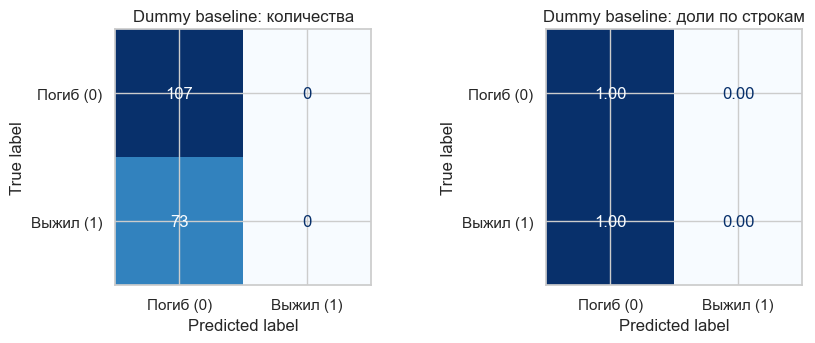

TN=107  FP=0  FN=73  TP=0


In [8]:
def calc_metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}


def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    labels = ["Погиб (0)", "Выжил (1)"]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"{title}: количества")
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1], normalize="true"),
                           display_labels=labels).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
    axes[1].set_title(f"{title}: доли по строкам")
    plt.tight_layout(); plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")


RES = {}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
RES["Dummy baseline"] = {
    "model": dummy, "train": calc_metrics(y_train, dummy.predict(X_train)),
    "test": calc_metrics(y_test, dummy.predict(X_test)), "pred_test": dummy.predict(X_test), "cv_f1": np.nan}
print("Dummy предсказывает класс:", dummy.predict(X_test)[0])
display(pd.DataFrame(RES["Dummy baseline"]["test"], index=["hold-out"]).round(3))
plot_cm(y_test, RES["Dummy baseline"]["pred_test"], "Dummy baseline")

**Вывод.** Dummy-модель всегда отвечает «погиб»: Accuracy = 0.594 (доля класса 0 в hold-out), а Precision, Recall и F1 равны 0 — ни один из 73 выживших не найден (TP = 0, FN = 73). Accuracy у бесполезной модели выглядит «приличной», F1 — нет; это подтверждает выбор F1 основной метрикой. Любая модель должна быть заметно выше F1 = 0.

In [9]:
def run_model(name, clf, grid, scale=False, show_cm=True):
    """Подбор гиперпараметров групповой CV по F1 на обучающей части, затем оценка на ней и на hold-out."""
    pipe = make_pipe(clf, scale=scale)
    gs = GridSearchCV(pipe, {f"clf__{k}": v for k, v in grid.items()}, scoring="f1", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train, groups=g_train)
    best = gs.best_estimator_
    pred_tr, pred_te = best.predict(X_train), best.predict(X_test)
    RES[name] = {"model": best, "scale": scale, "params": gs.best_params_, "cv_f1": gs.best_score_,
                 "train": calc_metrics(y_train, pred_tr), "test": calc_metrics(y_test, pred_te), "pred_test": pred_te}
    print(f"{name}\n  лучшие параметры: { {k.replace('clf__', ''): v for k, v in gs.best_params_.items()} }")
    print(f"  CV F1 на обучающей части (5 фолдов): {gs.best_score_:.3f}")
    display(pd.DataFrame({"train-часть": RES[name]["train"], "hold-out": RES[name]["test"]}).T.round(3))
    if show_cm:
        plot_cm(y_test, pred_te, name)
    return gs

## 6. Модели

Гиперпараметры подбираются `GridSearchCV` на обучающей части (5-fold, стратификация + группировка дубликатов, метрика F1) — **одинаковая процедура и одинаковые фолды для всех моделей**. Hold-out не используется до финальной оценки.

**Бюджет подбора не выравнивался:** размеры сеток разные (Decision Tree — 70 комбинаций, Gradient Boosting — 54, Random Forest и KNN — по 32, SVM — 25, и только с RBF-ядром). На выводы это, скорее всего, не влияет, но по числу проб подбор не «одинаков»: одинаковы метрика, фолды и данные.

**Что такое FP и FN в этой задаче**
- **False Positive** — модель предсказала «выжил», а пассажир погиб. Модель излишне оптимистична; снижает **Precision**.
- **False Negative** — модель предсказала «погиб», а пассажир выжил. Модель «похоронила» выжившего; снижает **Recall**.

Цена ошибок симметрична (мы оцениваем качество прогноза, а не принимаем решение о спасении), поэтому важен баланс — отсюда F1.

### 6.1 Decision Tree
Сначала дерево **без ограничений** — чтобы увидеть переобучение, затем кривая по `max_depth` (CV на обучающей части) и дерево с подобранными параметрами.

Дерево без ограничений: глубина = 15 , листьев = 161


,Accuracy,Precision,Recall,F1
train-часть,0.986,1.000,0.963,0.981
hold-out,0.800,0.794,0.685,0.735


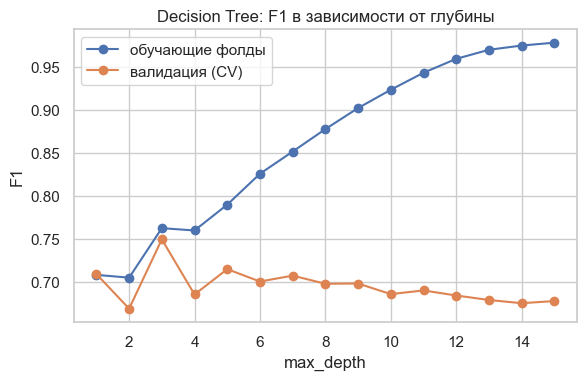

Лучшая глубина по CV: 3  F1 = 0.749


In [10]:
dt_full = make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(X_train, y_train)
dt_full_res = pd.DataFrame({"train-часть": calc_metrics(y_train, dt_full.predict(X_train)),
                            "hold-out": calc_metrics(y_test, dt_full.predict(X_test))}).T
print("Дерево без ограничений: глубина =", dt_full.named_steps["clf"].get_depth(),
      ", листьев =", dt_full.named_steps["clf"].get_n_leaves())
display(dt_full_res.round(3))

depths = list(range(1, 16))
tr_sc, va_sc = validation_curve(make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train, y_train, groups=g_train,
                                param_name="clf__max_depth", param_range=depths, cv=cv, scoring="f1", n_jobs=-1)
plt.figure(figsize=(6.5, 3.8))
plt.plot(depths, tr_sc.mean(1), "o-", label="обучающие фолды")
plt.plot(depths, va_sc.mean(1), "o-", label="валидация (CV)")
plt.xlabel("max_depth"); plt.ylabel("F1"); plt.title("Decision Tree: F1 в зависимости от глубины"); plt.legend(); plt.show()
print("Лучшая глубина по CV:", depths[int(va_sc.mean(1).argmax())], " F1 = %.3f" % va_sc.mean(1).max())

Decision Tree
  лучшие параметры: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 3}
  CV F1 на обучающей части (5 фолдов): 0.752


,Accuracy,Precision,Recall,F1
train-часть,0.828,0.810,0.714,0.759
hold-out,0.806,0.806,0.685,0.741


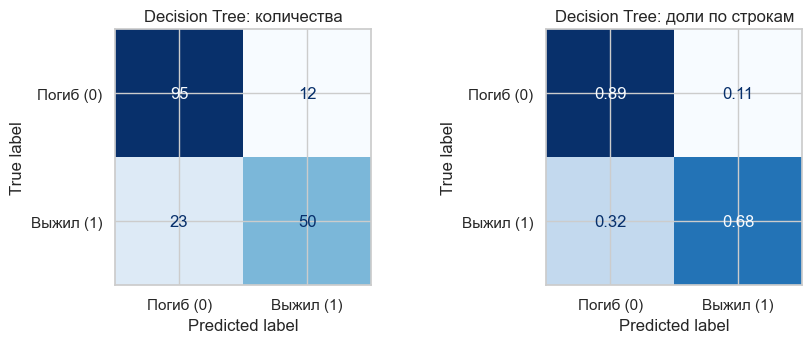

TN=95  FP=12  FN=23  TP=50


In [11]:
gs_dt = run_model("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),
                  {"max_depth": [2, 3, 4, 5, 6, 8, 10], "min_samples_leaf": [1, 3, 5, 10, 20],
                   "criterion": ["gini", "entropy"]})

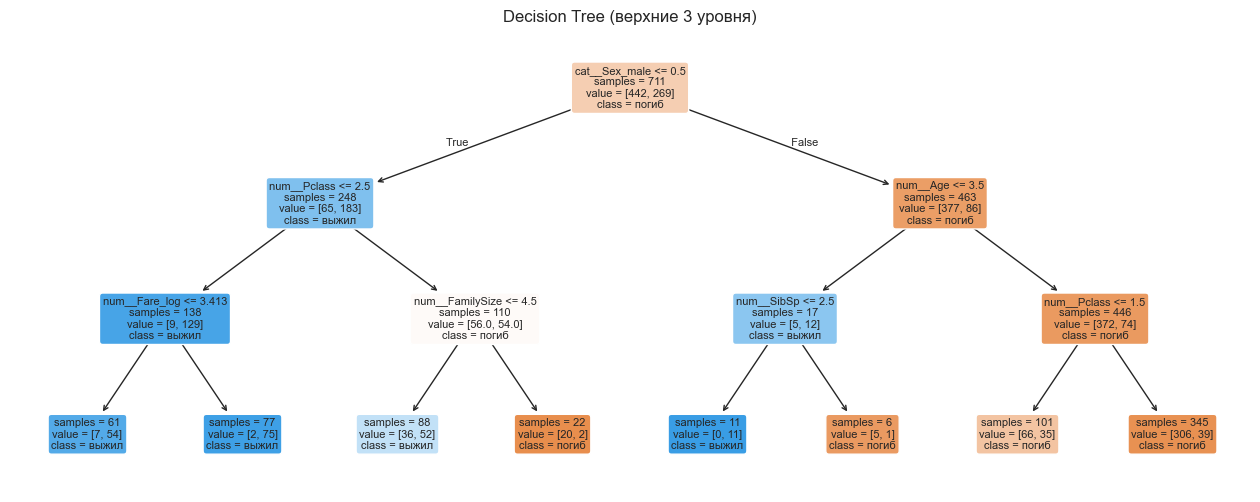

In [12]:
feat_names = list(RES["Decision Tree"]["model"].named_steps["pre"].get_feature_names_out())
plt.figure(figsize=(16, 6))
plot_tree(RES["Decision Tree"]["model"].named_steps["clf"], feature_names=feat_names, class_names=["погиб", "выжил"],
          max_depth=3, filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Decision Tree (верхние 3 уровня)"); plt.show()

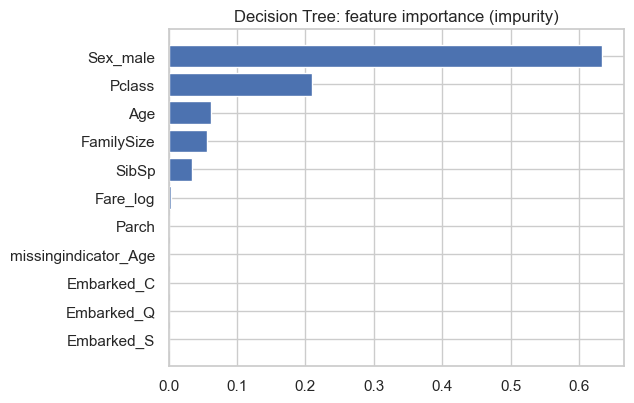

,cat__Sex_male,num__Pclass,num__Age,num__FamilySize,num__SibSp,num__Fare_log,num__Parch,num__missingindicator_Age
importance,0.634,0.21,0.061,0.057,0.035,0.003,0.0,0.0


In [13]:
def importance_table(name):
    m = RES[name]["model"]
    names = m.named_steps["pre"].get_feature_names_out()
    return pd.Series(m.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)


def plot_importance(name, top=12):
    imp = importance_table(name).head(top)[::-1]
    plt.figure(figsize=(6.5, 4.2))
    plt.barh([i.split("__", 1)[1] for i in imp.index], imp.values, color="#4c72b0")
    plt.title(f"{name}: feature importance (impurity)")
    plt.tight_layout(); plt.show()


plot_importance("Decision Tree")
display(importance_table("Decision Tree").head(8).round(3).to_frame("importance").T)

**Выводы по Decision Tree**

- **Без ограничений** дерево вырастает до глубины 15 (161 лист): F1 на train-части = 0.981, на hold-out = 0.735; accuracy 0.986 → 0.800. Это явное **переобучение** — дерево запомнило обучающие объекты. Кривая показывает то же: F1 на обучающих фолдах растёт с глубиной почти до 1, а валидационный максимум (≈ 0.75) — при `max_depth = 3`.
- **Дерево с подобранными параметрами** (`max_depth = 3`, `min_samples_leaf = 3`): F1 train-часть / hold-out = 0.759 / 0.741, accuracy 0.828 / 0.806, CV F1 = 0.752. Разрыв небольшой → **выраженного переобучения нет**.
- Ошибки на hold-out: FP = 12, FN = 23; Precision = 0.806, Recall = 0.685 (из 73 выживших найдено 50). Дерево консервативно: чаще пропускает выживших.
- **Что выучило дерево:** «предсказать "выжил" для женщин (кроме 3 класса при семье > 4 человек) и для маленьких мальчиков (≤ 3.5 лет, SibSp ≤ 2); всех остальных — "погиб"». Это ровно правило «женщины и дети первыми» с поправкой на класс.
- **Feature importance:** `Sex` — 0.63, `Pclass` — 0.21, `Age` — 0.06, `FamilySize` — 0.06, `SibSp` — 0.04; `Fare_log`, `Parch`, `Embarked` и индикатор пропуска — практически 0. Дерево глубины 3 использует 6 признаков, но `Fare_log` (0.003) делит ветку «женщины 1–2 классов», где обе стороны дают один и тот же класс, то есть на предсказание не влияет; фактически работают 5 признаков.

### 6.2 Random Forest

Random Forest
  лучшие параметры: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 300}
  CV F1 на обучающей части (5 фолдов): 0.755


,Accuracy,Precision,Recall,F1
train-часть,0.923,0.935,0.855,0.893
hold-out,0.828,0.828,0.726,0.774


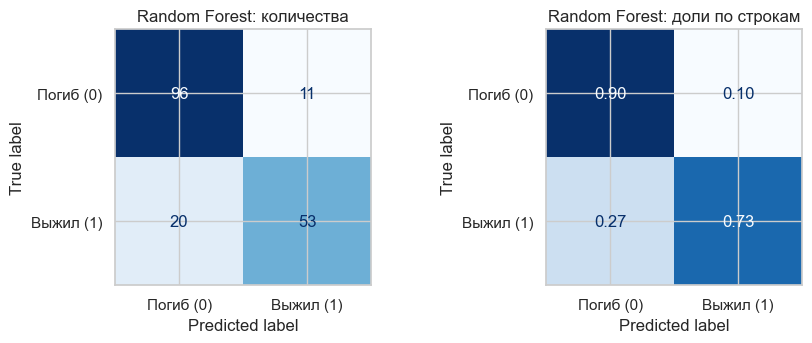

TN=96  FP=11  FN=20  TP=53


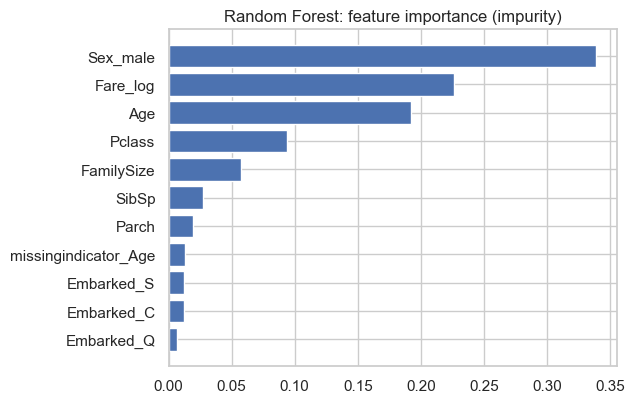

,cat__Sex_male,num__Fare_log,num__Age,num__Pclass,num__FamilySize,num__SibSp,num__Parch,num__missingindicator_Age
Decision Tree,0.634,0.003,0.061,0.210,0.057,0.035,0.000,0.000
Random Forest,0.339,0.226,0.192,0.094,0.058,0.027,0.019,0.013


In [14]:
gs_rf = run_model("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
                  {"n_estimators": [300], "max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 2, 4, 8],
                   "max_features": ["sqrt", 0.5]})
plot_importance("Random Forest")
cmp = pd.concat([importance_table("Decision Tree").rename("Decision Tree"),
                 importance_table("Random Forest").rename("Random Forest")], axis=1).fillna(0)
display(cmp.sort_values("Random Forest", ascending=False).head(8).round(3).T)

**Выводы по Random Forest и сравнение с Decision Tree**

- Подобранные параметры: 300 деревьев, `max_depth = None`, `min_samples_leaf = 2`, `max_features = 0.5`. F1 train-часть / hold-out = 0.893 / 0.774, accuracy 0.923 / 0.828. Разрыв между train и hold-out заметный (0.12 по F1) — отдельные деревья леса переобучены, но усреднение сохраняет качество на новых данных: hold-out F1 лучший среди всех моделей.
- **Сравнение с деревом:** F1 на hold-out 0.774 против 0.741 (разница ≈ 3 правильных объекта), по CV на train-части 0.755 против 0.752 — то есть преимущество леса небольшое и в пределах шума (раздел 7). Лес пропускает меньше выживших: Recall 0.726 против 0.685 (FN = 20 против 23).
- **Важность признаков:** одиночное дерево отдаёт `Sex` 0.63 и `Pclass` 0.21, а `Fare_log` почти не использует (0.003). Лес распределяет её шире: `Sex` 0.34, `Fare_log` 0.23, `Age` 0.19, `Pclass` 0.09, `FamilySize` 0.06. Причины: (1) лес строит глубокие деревья и использует непрерывные признаки (`Age`, `Fare`) для многих мелких разбиений; (2) `max_features = 0.5` заставляет разные деревья опираться на разные признаки; (3) impurity-важность завышает именно непрерывные признаки — реальный вклад `Fare_log` и `Age` существенно меньше (раздел 8). Общий состав главных признаков тот же: пол, класс, возраст.

### 6.3 Gradient Boosting

Gradient Boosting
  лучшие параметры: {'learning_rate': 0.02, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.7}
  CV F1 на обучающей части (5 фолдов): 0.755


,Accuracy,Precision,Recall,F1
train-часть,0.923,0.946,0.844,0.892
hold-out,0.828,0.828,0.726,0.774


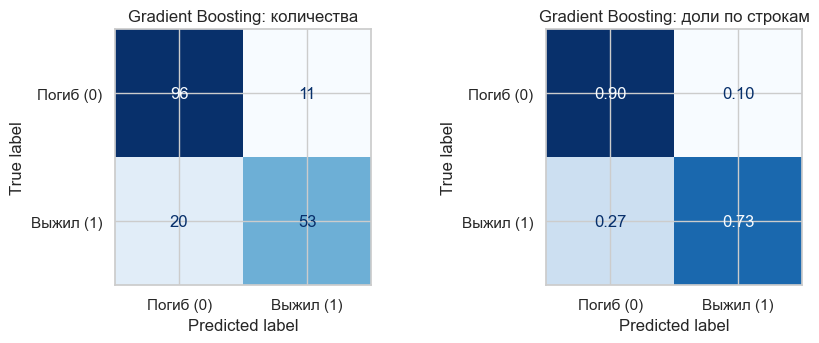

TN=96  FP=11  FN=20  TP=53


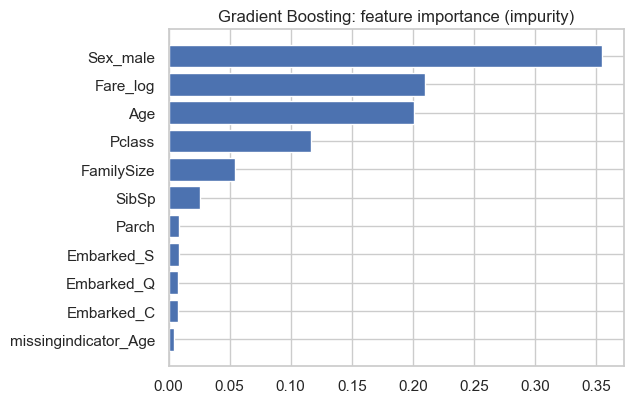

,cat__Sex_male,num__Fare_log,num__Age,num__Pclass,num__FamilySize,num__SibSp,num__Parch,cat__Embarked_S
Random Forest,0.339,0.226,0.192,0.094,0.058,0.027,0.019,0.012
Gradient Boosting,0.355,0.210,0.201,0.117,0.054,0.025,0.009,0.009


In [15]:
gs_gb = run_model("Gradient Boosting", GradientBoostingClassifier(random_state=RANDOM_STATE),
                  {"n_estimators": [100, 200, 300], "learning_rate": [0.02, 0.05, 0.1],
                   "max_depth": [2, 3, 4], "subsample": [0.7, 1.0]})
plot_importance("Gradient Boosting")
cmp = pd.concat([importance_table("Random Forest").rename("Random Forest"),
                 importance_table("Gradient Boosting").rename("Gradient Boosting")], axis=1).fillna(0)
display(cmp.sort_values("Gradient Boosting", ascending=False).head(8).round(3).T)

**Выводы по Gradient Boosting и сравнение с Random Forest**

- Параметры: 300 деревьев глубины 4, `learning_rate = 0.02`, `subsample = 0.7`. F1 train-часть / hold-out = 0.892 / 0.774, accuracy 0.923 / 0.828 — те же значения, что и у Random Forest; матрицы ошибок совпадают по числам (FP = 11, FN = 20), хотя предсказания двух моделей различаются на 4 объектах из 180.
- **Сравнение с RF:** качество на hold-out одинаково (0.774), по CV на train-части совпадает (0.755 у обоих), а по повторной CV на всём train GB чуть выше (0.766 против 0.762 — различие в пределах шума). Разрыв train/hold-out одинаков (≈ 0.12): обе модели подгоняются под train сильнее, чем дерево, но на новых данных не проигрывают.
- **Важность признаков почти совпадает:** у GB `Sex` 0.36, `Fare_log` 0.21, `Age` 0.20, `Pclass` 0.12 против 0.34 / 0.23 / 0.19 / 0.09 у леса. Бустинг чуть больше опирается на `Pclass` и `Sex`, лес — на `Fare_log`. Это закономерно: в обоих случаях ансамбли деревьев, а набор признаков и сильные сигналы (пол, класс) одни и те же.

### 6.4 Support Vector Machine

Сначала проверяем на кросс-валидации (обучающая часть), как влияет масштабирование при параметрах по умолчанию, затем подбираем параметры на масштабированных данных.

,без масштабирования,со StandardScaler
"CV F1, SVC по умолчанию",0.12,0.745


SVM
  лучшие параметры: {'C': 10, 'gamma': 0.03, 'kernel': 'rbf'}
  CV F1 на обучающей части (5 фолдов): 0.757


,Accuracy,Precision,Recall,F1
train-часть,0.835,0.825,0.717,0.767
hold-out,0.800,0.814,0.658,0.727


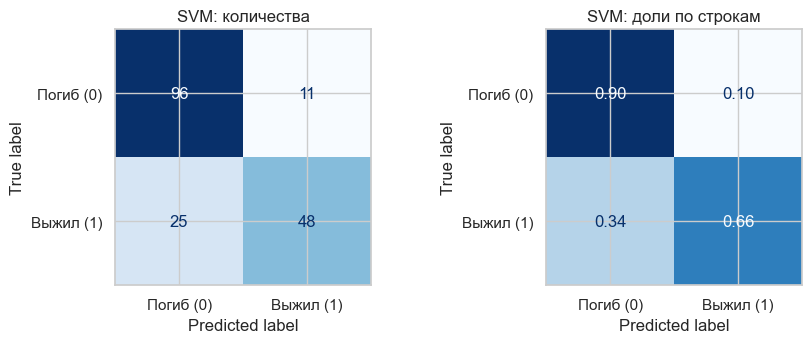

TN=96  FP=11  FN=25  TP=48


In [16]:
def cv_f1(pipe):
    return cross_val_score(pipe, X_train, y_train, groups=g_train, cv=cv, scoring="f1", n_jobs=-1).mean()

svm_scale = pd.Series({"без масштабирования": cv_f1(make_pipe(SVC(), scale=False)),
                       "со StandardScaler": cv_f1(make_pipe(SVC(), scale=True))}, name="CV F1, SVC по умолчанию")
display(svm_scale.round(3).to_frame().T)

gs_svm = run_model("SVM", SVC(), {"C": [0.3, 1, 3, 10, 30], "gamma": ["scale", 0.01, 0.03, 0.1, 0.3], "kernel": ["rbf"]}, scale=True)

**Выводы по SVM**

- **Масштабирование необходимо.** SVC с параметрами по умолчанию: CV F1 = 0.12 без масштабирования и 0.745 со `StandardScaler`. RBF-ядро строит решение по евклидову расстоянию: без масштаба расстояние почти целиком определяется `Age` (0–80), а бинарные признаки (пол, порт) и `Pclass` практически «не слышны» — модель почти не находит выживших (F1 0.12). Стандартизация приводит числовые признаки к единой шкале; бинарные one-hot-признаки остаются в шкале 0/1 (std ≈ 0.3–0.5), так что вклад признаков сопоставим, но не идентичен.
- После подбора (`C = 10`, `gamma = 0.03`): F1 train-часть / hold-out = 0.767 / 0.727, accuracy 0.835 / 0.800, Precision = 0.814, Recall = 0.658 (FP = 11, FN = 25). Переобучения нет (разрыв 0.04), но модель осторожнее остальных: наименьший Recall и наименьший hold-out F1 из пяти.
- При этом по CV на train-части SVM — лучший (0.757), а по повторной CV на всём train — 0.751. Худший результат на hold-out, вероятно, шум малой выборки (bootstrap-интервалы моделей перекрываются), но строго доказать это нельзя.

### 6.5 K-Nearest Neighbors

,без масштабирования,со StandardScaler
"CV F1, KNN по умолчанию",0.638,0.674


KNN
  лучшие параметры: {'n_neighbors': 21, 'p': 1, 'weights': 'distance'}
  CV F1 на обучающей части (5 фолдов): 0.715


,Accuracy,Precision,Recall,F1
train-часть,0.986,1.000,0.963,0.981
hold-out,0.800,0.803,0.671,0.731


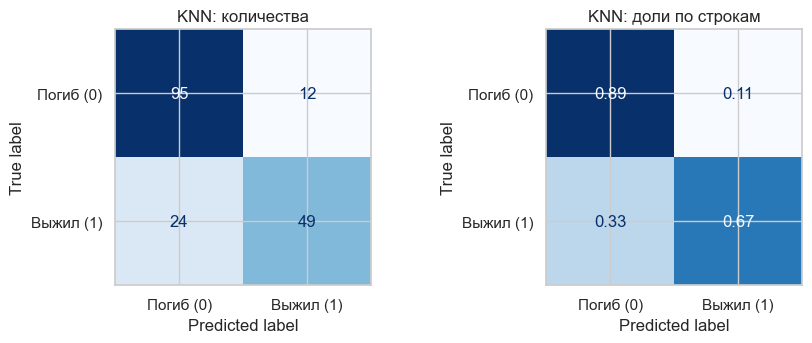

TN=95  FP=12  FN=24  TP=49


In [17]:
knn_scale = pd.Series({"без масштабирования": cv_f1(make_pipe(KNeighborsClassifier(), scale=False)),
                       "со StandardScaler": cv_f1(make_pipe(KNeighborsClassifier(), scale=True))}, name="CV F1, KNN по умолчанию")
display(knn_scale.round(3).to_frame().T)

gs_knn = run_model("KNN", KNeighborsClassifier(),
                   {"n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "weights": ["uniform", "distance"], "p": [1, 2]}, scale=True)

**Выводы по KNN**

- **Масштаб важен принципиально**, потому что KNN целиком состоит из расстояний: «ближайшие» объекты определяются суммой разностей по признакам, и признак с большим диапазоном (`Age`) перетягивает метрику. Но на этих данных эффект **умеренный**: CV F1 при `k = 5` — 0.638 без масштабирования и 0.674 со `StandardScaler` (+3.6 п.п.), в отличие от SVM (0.12 → 0.745). Часть эффекта скрыта тем, что вместо `Fare` уже используется `Fare_log`: разброс шкал меньше, чем у исходных признаков.
- После подбора (`k = 21`, манхэттенское расстояние `p = 1`, `weights = distance`): F1 hold-out = 0.731, accuracy 0.800, Precision 0.803, Recall 0.671; CV F1 = 0.715 — **самый низкий из пяти** и по повторной CV на всём train (0.735). Возможная причина: после one-hot у KNN 11 признаков с равным весом, и малоинформативные (`Parch`, `SibSp`, `Embarked`, индикатор пропуска) добавляют шум в расстояние; деревья такие признаки просто игнорируют.
- **Про F1 на train-части = 0.981:** это артефакт `weights = distance` — каждая обучающая точка является своим ближайшим соседом с нулевым расстоянием, поэтому её метка предсказывается правильно по построению. Сравнение train/hold-out для KNN неинформативно; честная оценка — CV и hold-out.

## 7. Честное сравнение моделей

Все модели: одни и те же `X_train`/`X_test`, одинаковая предобработка (масштабирование — только там, где оно нужно по природе алгоритма), одинаковая процедура подбора (групповая CV по F1 на обучающей части, одни и те же фолды), `random_state = 42`. Сортировка — по F1 на hold-out. Гиперпараметры, предобработка и набор признаков по hold-out не подбирались; он используется для оценки и определения лидера. Если у нескольких моделей F1 на hold-out совпадает (до 3 знаков), «лучшей» считается та, у которой выше средний F1 по повторной групповой CV на всём `train.csv` (правило задано заранее; эта оценка уже не независима от hold-out, а гиперпараметры подбирались на части тех же данных, поэтому она слегка оптимистична, но одинаково для всех моделей).

Hold-out мал (~180 объектов), поэтому приведён 95%-й bootstrap-интервал для F1 (1000 ресэмплов предсказаний): он показывает, какие различия между моделями неотличимы от шума. Колонка `CV F1` — оценка по 5 фолдам обучающей части, она устойчивее, чем один hold-out.

,Accuracy,Precision,Recall,F1,F1 95% CI (bootstrap),F1 > 0.70,CV F1,F1 train-часть
Модель,,,,,,,,
Random Forest,0.828,0.828,0.726,0.774,"[0.69, 0.84]",да,0.755,0.893
Gradient Boosting,0.828,0.828,0.726,0.774,"[0.69, 0.84]",да,0.755,0.892
Decision Tree,0.806,0.806,0.685,0.741,"[0.66, 0.81]",да,0.752,0.759
KNN,0.800,0.803,0.671,0.731,"[0.64, 0.81]",да,0.715,0.981
SVM,0.800,0.814,0.658,0.727,"[0.64, 0.80]",да,0.757,0.767
Dummy baseline,0.594,0.000,0.000,0.000,"[0.00, 0.00]",нет,NaN,0.000


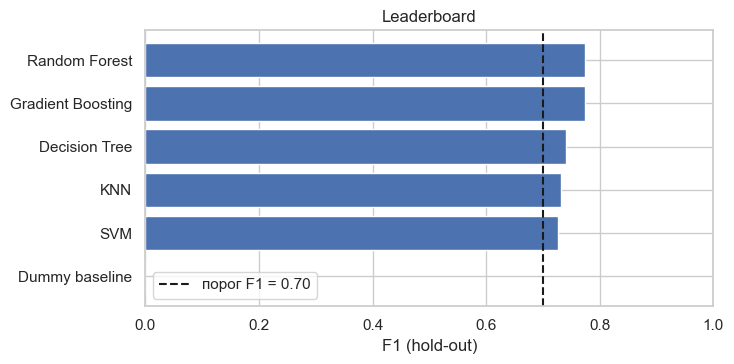

,"F1, среднее (3×5 фолдов, весь train)",std по фолдам
Gradient Boosting,0.766,0.043
Random Forest,0.762,0.041
SVM,0.751,0.057
Decision Tree,0.749,0.053
KNN,0.735,0.034


Лидеры по F1 на hold-out (с округлением до 3 знаков): ['Random Forest', 'Gradient Boosting'] → лучшая модель по правилу: Gradient Boosting


In [18]:
order = ["Dummy baseline", "Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]
rng = np.random.RandomState(RANDOM_STATE)
boot_idx = [rng.randint(0, len(y_test), len(y_test)) for _ in range(1000)]
yt = y_test.values


def f1_ci(pred):
    s = [f1_score(yt[i], pred[i], zero_division=0) for i in boot_idx]
    return np.percentile(s, [2.5, 97.5])


rows = []
for n in order:
    r = RES[n]
    lo, hi = f1_ci(r["pred_test"])
    rows.append({"Модель": n, **{k: r["test"][k] for k in ["Accuracy", "Precision", "Recall", "F1"]},
                 "F1 95% CI (bootstrap)": f"[{lo:.2f}, {hi:.2f}]", "F1 > 0.70": "да" if r["test"]["F1"] > F1_THRESHOLD else "нет",
                 "CV F1": r["cv_f1"], "F1 train-часть": r["train"]["F1"]})
leader = pd.DataFrame(rows).set_index("Модель").sort_values("F1", ascending=False)
display(leader.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ordered = leader.index.tolist()[::-1]
ax.barh(ordered, leader.loc[ordered, "F1"], color=["#c44e52" if leader.loc[m, "F1"] <= F1_THRESHOLD else "#4c72b0" for m in ordered])
ax.axvline(F1_THRESHOLD, color="k", ls="--", label="порог F1 = 0.70"); ax.set_xlabel("F1 (hold-out)"); ax.legend(); ax.set_xlim(0, 1)
plt.title("Leaderboard"); plt.tight_layout(); plt.show()

Xf_all = add_features(X)
cand_names = [n for n in order if n != "Dummy baseline"]
rep_scores = {}
for n in cand_names:
    sc = []
    for sd in range(3):
        cv_r = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=100 + sd)
        sc.append(cross_val_score(clone(RES[n]["model"]), Xf_all, y, groups=groups_all, cv=cv_r, scoring="f1", n_jobs=-1))
    rep_scores[n] = np.concatenate(sc)
REP = "F1, среднее (3×5 фолдов, весь train)"
sel = pd.DataFrame({n: {REP: v.mean(), "std по фолдам": v.std()} for n, v in rep_scores.items()}).T
display(sel.sort_values(REP, ascending=False).round(3))

rank = leader.drop(index="Dummy baseline").assign(F1r=lambda d: d.F1.round(3), rep=sel[REP])
best_name = rank.sort_values(["F1r", "rep"], ascending=False).index[0]
ties = rank.index[rank.F1r == rank.F1r.max()].tolist()
print("Лидеры по F1 на hold-out (с округлением до 3 знаков):", ties, "→ лучшая модель по правилу:", best_name)

**Выводы по сравнению**

| Модель | F1 (hold-out) | CV F1 (обуч. часть) | F1, повторная CV на всём train | F1 > 0.70 на hold-out |
|---|---|---|---|---|
| Random Forest | 0.774 | 0.755 | 0.762 | да |
| Gradient Boosting | 0.774 | 0.755 | 0.766 | да |
| Decision Tree | 0.741 | 0.752 | 0.749 | да |
| KNN | 0.731 | 0.715 | 0.735 | да |
| SVM | 0.727 | 0.757 | 0.751 | да |
| Dummy baseline | 0.000 | — | — | нет |

(Колонка «повторная CV на всём train» посчитана в разделе 10.)

- **Порог F1 > 0.70 превзошли все пять моделей** на hold-out; по всем вариантам кросс-валидации средний F1 тоже выше 0.70 (0.715–0.766). Baseline с F1 = 0 порог не проходит.
- **Но различия между моделями статистически не значимы.** Bootstrap-интервалы F1 на hold-out (180 объектов) шириной ≈ ±0.08 сильно перекрываются, а нижние границы (0.64–0.69) ниже 0.70: «выше порога» только на этом hold-out строго не доказано. Разброс между лучшей и худшей моделью (0.774 против 0.727) — это 3–4 объекта. Порядок по hold-out и по CV разный (SVM — последняя по hold-out, но лучшая по CV на обучающей части), поэтому утверждать «ансамбли лучше SVM» нельзя. Устойчивый вывод один: **KNN слабее остальных** по обеим CV (0.715 и 0.735), четыре остальные модели практически неразличимы (0.749–0.766 при std по фолдам 0.03–0.06).
- **Причины различий и сходства:**
  1. Сильных признаков мало (пол, класс, отчасти возраст и семья), и простая граница уже почти оптимальна — неглубокое дерево получает 0.75, а сложные ансамбли не могут добавить много;
  2. при наличии 16 групп с одинаковыми признаками и разными ответами у задачи есть потолок качества;
  3. SVM и KNN работают только после масштабирования (без него F1 0.12 и 0.64), и KNN при этом всё равно слабее из-за чувствительности к шумовым признакам;
  4. датасет мал: в hold-out 73 выживших, один объект меняет Recall на 1.4 п.п.; hold-out F1 лучшей модели (0.774) выше, чем её среднее по 10 разным групповым разбиениям (0.763, раздел 9), — на этом разбиении модели немного повезло.

## 8. Feature Importance

Для Decision Tree, Random Forest и Gradient Boosting используем два вида важности:

1. **Impurity-based** (`feature_importances_`) — вклад признака в уменьшение неопределённости, считается по обучающей части. Известный недостаток: завышает важность непрерывных и многозначных признаков (`Age`, `Fare`). One-hot-столбцы суммируем по исходному признаку.
2. **Permutation importance** — падение F1 при случайном перемешивании признака. Чтобы не трогать hold-out, считаем на отложенных фолдах **внутри обучающей части** (5-fold групповых, 5 повторов), по исходным признакам.

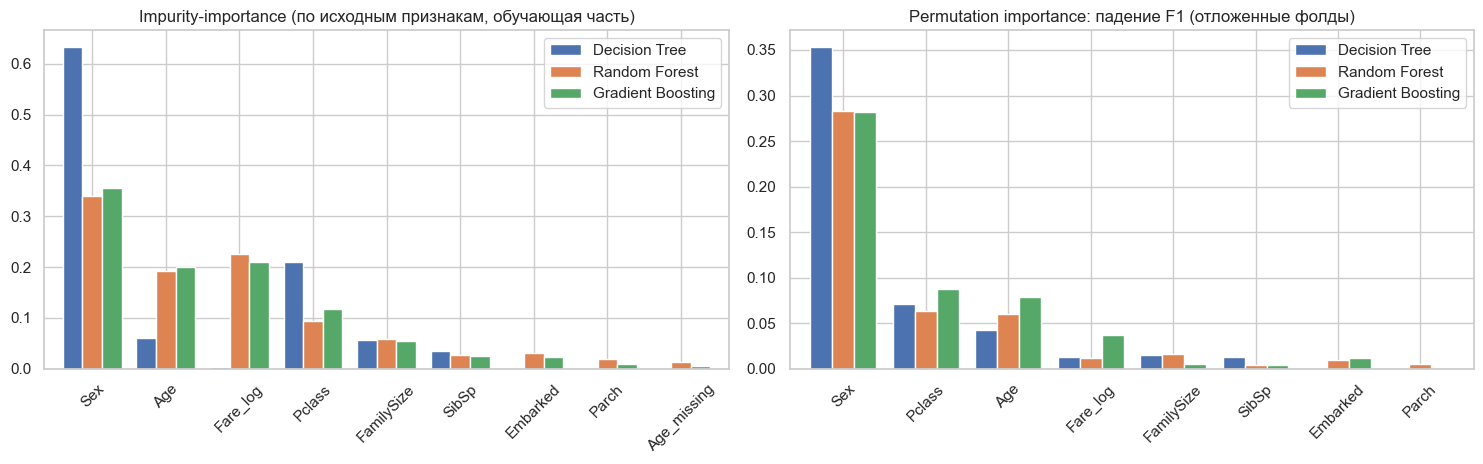

,Sex,Age,Fare_log,Pclass,FamilySize,SibSp,Embarked,Parch,Age_missing
Decision Tree,0.634,0.061,0.003,0.210,0.057,0.035,0.000,0.000,0.000
Random Forest,0.339,0.192,0.226,0.094,0.058,0.027,0.031,0.019,0.013
Gradient Boosting,0.355,0.201,0.210,0.117,0.054,0.025,0.024,0.009,0.005


,Sex,Pclass,Age,Fare_log,FamilySize,SibSp,Embarked,Parch
Decision Tree,0.354,0.071,0.042,0.013,0.015,0.013,0.000,0.000
Random Forest,0.283,0.064,0.060,0.012,0.017,0.004,0.010,0.005
Gradient Boosting,0.281,0.087,0.079,0.037,0.005,0.004,0.011,0.000


In [19]:
def orig_name(n):
    n = n.split("__", 1)[1]
    if n.startswith("missingindicator_"):
        return n.replace("missingindicator_", "") + "_missing"
    return n.split("_")[0] if n.split("_")[0] in CAT else n


def agg_importance(name):
    s = importance_table(name)
    s.index = [orig_name(i) for i in s.index]
    return s.groupby(level=0).sum()


FI_MODELS = ["Decision Tree", "Random Forest", "Gradient Boosting"]
imp_impurity = pd.concat({n: agg_importance(n) for n in FI_MODELS}, axis=1).fillna(0)
imp_impurity = imp_impurity.loc[imp_impurity.mean(axis=1).sort_values(ascending=False).index]

feats = NUM + CAT
perm = {}
for n in FI_MODELS:
    base = RES[n]["model"]
    acc = []
    for tri, vai in cv.split(X_train, y_train, g_train):
        m = clone(base).fit(X_train.iloc[tri], y_train.iloc[tri])
        r = permutation_importance(m, X_train.iloc[vai][feats], y_train.iloc[vai], scoring="f1",
                                   n_repeats=5, random_state=RANDOM_STATE)
        acc.append(r.importances_mean)
    perm[n] = pd.Series(np.mean(acc, axis=0), index=feats)
imp_perm = pd.DataFrame(perm)
imp_perm = imp_perm.loc[imp_perm.mean(axis=1).sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
imp_impurity.plot.bar(ax=axes[0], width=0.8); axes[0].set_title("Impurity-importance (по исходным признакам, обучающая часть)")
imp_perm.plot.bar(ax=axes[1], width=0.8); axes[1].set_title("Permutation importance: падение F1 (отложенные фолды)")
for a in axes: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

display(imp_impurity.round(3).T)
display(imp_perm.round(3).T)

**Выводы по feature importance**

1. **Визуализация** — две диаграммы выше (impurity и permutation по исходным признакам).
2. **Наиболее важные признаки.** Во всех трёх моделях безусловный лидер — `Sex`. Дальше картина зависит от способа расчёта. **По permutation-важности** (надёжнее): `Sex` 0.35 / 0.28 / 0.28 (DT / RF / GB), затем `Pclass` 0.07 / 0.06 / 0.09 и `Age` 0.04 / 0.06 / 0.08; `Fare_log` 0.01 / 0.01 / 0.04, `FamilySize` ≤ 0.02. **По impurity** у RF и GB вторым идёт `Fare_log` (0.23 / 0.21), затем `Age` (0.19 / 0.20), а `Pclass` — только четвёртый (0.09 / 0.12); у дерева `Sex` 0.63 и `Pclass` 0.21. Расхождение объясняется завышением непрерывных признаков в impurity (п. 4). `Embarked`, `SibSp`, `Parch`, индикатор пропуска `Age` — близки к нулю (`Embarked` у RF и GB 0.03 и 0.02 по impurity).
3. **Сравнение моделей:** дерево сосредоточено на `Sex` (0.63) и `Pclass` (0.21) и почти не использует `Fare_log`; RF и GB распределяют важность по пяти признакам (`Sex` ≈ 0.35, `Fare_log` ≈ 0.21–0.23, `Age` ≈ 0.19–0.20, `Pclass` 0.09–0.12) и между собой почти не различаются. Лидер общий (`Sex`); состав следующих мест зависит от метода: по permutation — класс и возраст, по impurity для ансамблей — плата и возраст.
4. **Impurity против permutation.** Impurity-важность завышает непрерывные признаки: в RF `Fare_log` имеет 0.23, а перестановка на отложенных данных снижает F1 всего на 0.012; у `Age` — 0.19 против 0.06. Это типичный эффект: непрерывные признаки дают много возможных порогов и часто выбираются для разбиений, в том числе шумовых. Permutation-важность честнее: она показывает, что реальный вклад вносят в основном `Sex`, `Pclass` и `Age`.
5. **Сопоставление с EDA:** согласуется — пол (73.8% против 18.6%), класс (61% → 23%), нелинейный размер семьи (дерево делит по `FamilySize ≤ 4.5`; 5+ человек — 13.7% выживших), дети. `Fare` почти дублирует класс (EDA: средняя плата 80 / 20 / 13), поэтому его самостоятельная важность низкая. `Embarked` в EDA различался (C 51.5%, S 33.9%); модели используют его слабо (impurity 0.02–0.03, permutation ≈ 0.01), а удаление признака снижает CV F1 лишь на 1.4 п.п. (в пределах шума, раздел 9). Эффект порта отчасти объясняется составом классов, но независимый вклад порта мал или неотличим от шума.

**Можно ли утверждать, что важный для модели признак является причиной выживания? Нет.**
- Важность показывает, на какие признаки модель **опирается при прогнозе**, то есть ассоциацию, а не причинный эффект. Данные наблюдательные, без вмешательств: смена пола или класса билета у конкретного человека не изменила бы, что с ним произошло.
- `Sex` и `Age` — маркеры политики эвакуации («женщины и дети первыми»); причиной была сама эта практика и доступ к шлюпкам. `Pclass` — прокси расположения палубы, близости к шлюпкам и социального статуса.
- Коррелированные признаки делят важность произвольно (`Pclass` и `Fare_log` взаимозаменяемы, `SibSp`, `Parch` и `FamilySize` связаны арифметически), поэтому значение зависит от модели и способа расчёта и не является «мерой причины».
- Не учтены ненаблюдаемые факторы (где находился пассажир, был ли в группе, знание языка и т.д.), которые могут влиять на исход и коррелировать с признаками.

## 9. Анализ ошибок лучшей модели

Лучшая модель выбрана по правилу из раздела 7 (лидер по F1 на hold-out, при равенстве — по повторной CV); это та же модель, что идёт в посылку. Дальше — разбор её ошибок по группам пассажиров, разбор конкретных объектов и проверка на «подозрительные» признаки.

Лучшая модель: Gradient Boosting


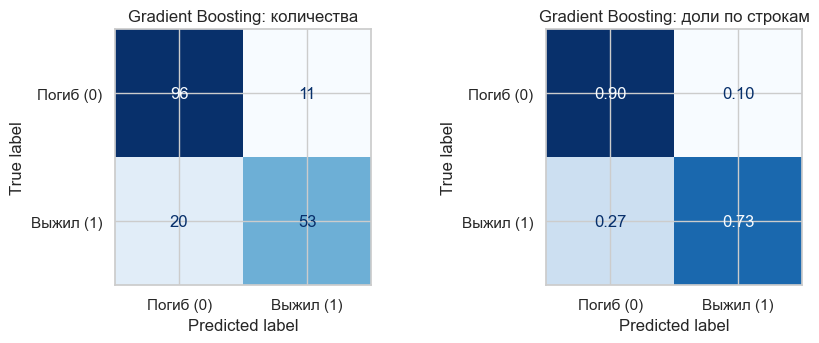

TN=96  FP=11  FN=20  TP=53
Ошибок всего: 31 из 180  (FP = 11, FN = 20)
Из погибших ошибочно названы выжившими (FPR): 0.103
Из выживших ошибочно названы погибшими (FNR): 0.274
Модель Random Forest с таким же F1 на hold-out: её предсказания отличаются от Gradient Boosting на 4 объектах из 180


In [20]:
best = RES[best_name]["model"]
pred = best.predict(X_test)
print("Лучшая модель:", best_name)
plot_cm(y_test, pred, best_name)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Ошибок всего: {fp + fn} из {len(y_test)}  (FP = {fp}, FN = {fn})")
print(f"Из погибших ошибочно названы выжившими (FPR): {fp / (fp + tn):.3f}")
print(f"Из выживших ошибочно названы погибшими (FNR): {fn / (fn + tp):.3f}")
for other in ties:
    if other != best_name:
        print(f"Модель {other} с таким же F1 на hold-out: её предсказания отличаются от {best_name} на {(RES[other]['pred_test'] != pred).sum()} объектах из {len(pred)}")

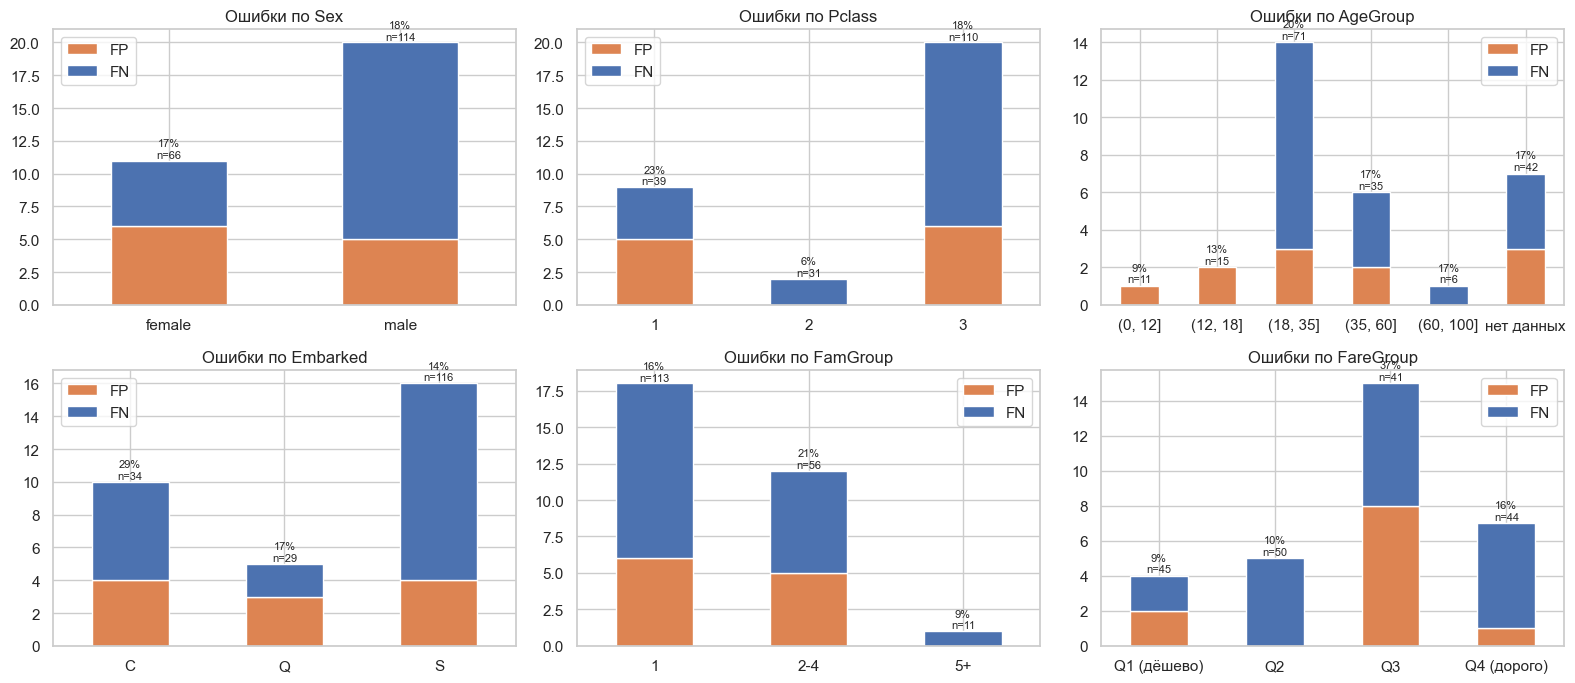

Sex,female,male
n,66.000,114.000
выжили,50.000,23.000
ошибок,11.000,20.000
FP,6.000,5.000
FN,5.000,15.000
доля ошибок,0.167,0.175


Pclass,1,2,3
n,39.000,31.000,110.000
выжили,28.000,15.000,30.000
ошибок,9.000,2.000,20.000
FP,5.000,0.000,6.000
FN,4.000,2.000,14.000
доля ошибок,0.231,0.065,0.182


AgeGroup,"(0, 12]","(12, 18]","(18, 35]","(35, 60]","(60, 100]",нет данных
n,11.000,15.000,71.000,35.000,6.000,42.000
выжили,10.000,3.000,28.000,13.000,3.000,16.000
ошибок,1.000,2.000,14.000,6.000,1.000,7.000
FP,1.000,2.000,3.000,2.000,0.000,3.000
FN,0.000,0.000,11.000,4.000,1.000,4.000
доля ошибок,0.091,0.133,0.197,0.171,0.167,0.167


Sex         female                 male                
Pclass           1     2       3      1       2       3
n             19.0  13.0  34.000  20.00  18.000  76.000
выжили        19.0  13.0  18.000   9.00   2.000  12.000
ошибок         0.0   0.0  11.000   9.00   2.000   9.000
FP             0.0   0.0   6.000   5.00   0.000   0.000
FN             0.0   0.0   5.000   4.00   2.000   9.000
доля_ошибок    0.0   0.0   0.324   0.45   0.111   0.118

In [21]:
def score(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


te = X_test.assign(y=y_test, pred=pred, score=score(best, X_test))
te["err"] = (te.y != te.pred).astype(int)
te["FN"] = ((te.y == 1) & (te.pred == 0)).astype(int)
te["FP"] = ((te.y == 0) & (te.pred == 1)).astype(int)
te["AgeGroup"] = np.where(te.Age.isna(), "нет данных", pd.cut(te.Age, [0, 12, 18, 35, 60, 100]).astype(str))
te["FamGroup"] = pd.cut(te.FamilySize, [0, 1, 4, 20], labels=["1", "2-4", "5+"]).astype(str)
te["FareGroup"] = pd.qcut(te.Fare, 4, labels=["Q1 (дёшево)", "Q2", "Q3", "Q4 (дорого)"]).astype(str)


def group_err(col):
    g = te.groupby(col).agg(n=("y", "size"), выжили=("y", "sum"), ошибок=("err", "sum"), FP=("FP", "sum"), FN=("FN", "sum"))
    g["доля ошибок"] = (g["ошибок"] / g["n"]).round(3)
    return g


fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, ["Sex", "Pclass", "AgeGroup", "Embarked", "FamGroup", "FareGroup"]):
    g = group_err(col)
    g[["FP", "FN"]].plot.bar(stacked=True, ax=ax, color=["#dd8452", "#4c72b0"])
    for i, (n, e) in enumerate(zip(g["n"], g["доля ошибок"])):
        ax.text(i, g[["FP", "FN"]].iloc[i].sum() + 0.2, f"{e:.0%}\nn={n}", ha="center", fontsize=8)
    ax.set_title(f"Ошибки по {col}"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

for col in ["Sex", "Pclass", "AgeGroup"]:
    display(group_err(col).T)
display(te.groupby(["Sex", "Pclass"]).agg(n=("y", "size"), выжили=("y", "sum"), ошибок=("err", "sum"), FP=("FP", "sum"), FN=("FN", "sum"),
                                         доля_ошибок=("err", "mean")).round(3).T)

In [22]:
cols = ["Id", "Sex", "Age", "Pclass", "Fare", "SibSp", "Parch", "Embarked", "y", "pred", "score"]
print("Самые уверенные False Positive (предсказан «выжил», на деле погиб):")
display(te[te.FP == 1].sort_values("score", ascending=False)[cols].head(5).round(2))
print("Самые уверенные False Negative (предсказан «погиб», на деле выжил):")
display(te[te.FN == 1].sort_values("score")[cols].head(5).round(2))

Самые уверенные False Positive (предсказан «выжил», на деле погиб):


,Id,Sex,Age,Pclass,Fare,SibSp,Parch,Embarked,y,pred,score
771,10000147,female,18.0,3,6.75,0,0,Q,0,1,0.80
690,10000066,female,32.0,3,15.50,1,1,Q,0,1,0.76
725,10000101,male,37.0,1,53.10,1,0,S,0,1,0.66
737,10000113,female,NaN,3,7.75,0,0,Q,0,1,0.65
13,72372244,female,31.0,3,18.00,1,0,S,0,1,0.61


Самые уверенные False Negative (предсказан «погиб», на деле выжил):


,Id,Sex,Age,Pclass,Fare,SibSp,Parch,Embarked,y,pred,score
20,56211872,female,38.0,3,31.39,1,5,S,1,0,0.05
686,10000062,male,80.0,1,30.00,0,0,S,1,0,0.07
162,41913454,male,19.0,2,10.50,0,0,S,1,0,0.07
208,26438145,male,NaN,3,23.25,2,0,Q,1,0,0.09
653,10000029,male,19.0,3,8.05,0,0,S,1,0,0.09


### Проверка на «идентифицирующие» и нежелательные признаки

1. **`Id`** — запрещён условием; добавляем его в набор, чтобы показать, что качество не растёт (а на глубоких моделях — что он провоцирует запоминание).
2. **`Age` и `Fare`** — почти уникальные числа; убираем по очереди, чтобы увидеть, не держится ли качество на них.
3. **Дубликаты:** сравниваем F1 при групповом и при обычном случайном разбиении. Если при обычном качество заметно выше, часть «успеха» — запоминание двойников, а не обобщение.

Гиперпараметры берём от лучшей модели; по CV (обучающая часть) и по hold-out — как диагностика, выбор модели по этому не меняется.

In [23]:
best_clf = best.named_steps["clf"]
best_scale = RES[best_name]["scale"]
variants = {
    "Основной набор": dict(),
    "+ Id (запрещён условием)": dict(num=NUM + ["Id"]),
    "− Fare_log": dict(num=[c for c in NUM if c != "Fare_log"]),
    "− Age": dict(num=[c for c in NUM if c != "Age"]),
    "− Embarked": dict(cat=["Sex"]),
}
rows = []
for label, kw in variants.items():
    p = make_pipe(clone(best_clf), scale=best_scale, **kw)
    cvs = cross_val_score(p, X_train, y_train, groups=g_train, cv=cv, scoring="f1", n_jobs=-1)
    p.fit(X_train, y_train)
    rows.append({"Вариант": label, "CV F1": cvs.mean(), "F1 train-часть": f1_score(y_train, p.predict(X_train)),
                 "F1 hold-out": f1_score(y_test, p.predict(X_test))})
display(pd.DataFrame(rows).set_index("Вариант").round(3))

# групповое vs обычное разбиение: среднее по 10 разбиениям (на одном разбиении шум ±0.03)
Xf = add_features(X)


def holdout_f1(model, tr_i, te_i):
    m = clone(model).fit(Xf.iloc[tr_i], y.iloc[tr_i])
    return f1_score(y.iloc[te_i], m.predict(Xf.iloc[te_i]))


models_cmp = {
    f"{best_name} (лучшие параметры)": make_pipe(clone(best_clf), scale=best_scale),
    "Decision Tree без ограничений": make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "KNN, k=1": make_pipe(KNeighborsClassifier(n_neighbors=1), scale=True),
}
rows = []
for label, mdl in models_cmp.items():
    g_sc, n_sc = [], []
    for sd in range(10):
        a_, b_ = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=sd).split(X, y, groups_all))
        g_sc.append(holdout_f1(mdl, a_, b_))
        a_, b_ = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y, random_state=sd)
        n_sc.append(holdout_f1(mdl, a_, b_))
    rows.append({"Модель": label, "F1, групповое разбиение": f"{np.mean(g_sc):.3f} ± {np.std(g_sc):.3f}",
                 "F1, обычное случайное разбиение": f"{np.mean(n_sc):.3f} ± {np.std(n_sc):.3f}", "разница": round(np.mean(n_sc) - np.mean(g_sc), 3)})
display(pd.DataFrame(rows).set_index("Модель"))

,CV F1,F1 train-часть,F1 hold-out
Вариант,,,
Основной набор,0.755,0.892,0.774
+ Id (запрещён условием),0.739,0.908,0.759
− Fare_log,0.723,0.848,0.774
− Age,0.717,0.848,0.763
− Embarked,0.741,0.884,0.768


,"F1, групповое разбиение","F1, обычное случайное разбиение",разница
Модель,,,
Gradient Boosting (лучшие параметры),0.763 ± 0.034,0.745 ± 0.047,-0.018
Decision Tree без ограничений,0.684 ± 0.033,0.698 ± 0.057,0.013
"KNN, k=1",0.663 ± 0.038,0.678 ± 0.056,0.016


**Выводы по анализу ошибок**

Лучшая модель выбрана по правилу из раздела 7: на hold-out Random Forest и Gradient Boosting имеют одинаковый F1 (0.774), при равенстве выбрана модель с большим F1 по повторной CV — **Gradient Boosting**; это же модель, которая идёт в посылку. Предсказания Random Forest отличаются от неё на 4 объектах из 180, так что выводы практически одинаковы.

**Типы ошибок.** 31 ошибка из 180 (17.2%): FP = 11, FN = 20. Ошибочно названы погибшими 27.4% выживших (20 из 73), ошибочно названы выжившими 10.3% погибших (11 из 107): модель в 2.7 раза чаще **пропускает выживших**, чем завышает шансы погибших — она консервативна (Precision 0.828 > Recall 0.726).

**Где модель ошибается больше всего** (группы малы, оценки приблизительные)
- **Пол × класс — ключевая картина.** Женщины 1–2 классов: 32 человека, все выжили, **0 ошибок**. Остальные группы — смешанные: женщины 3 класса — 11 ошибок из 34 (32%; 6 FP, 5 FN; выжила чуть больше половины), мужчины 1 класса — 9 из 20 (45%; 5 FP, 4 FN; выжили 9 из 20), мужчины 3 класса — 9 из 76 (12%; все FN: выжили 12 человек), мужчины 2 класса — 2 из 18 (оба FN). Модель ошибается там, где истинная выживаемость близка к 50%, а признаки не различают исходы внутри группы.
- **По полу:** мужчины — 20 ошибок (5 FP, 15 FN): пропущено 15 из 23 выживших мужчин; женщины — 11 ошибок (6 FP, 5 FN).
- **По классам:** 1 класс — 23% ошибок, 2 класс — 6%, 3 класс — 18%.
- **По возрасту:** дети до 18 лет — 3 ошибки из 26 (12%), 18–35 лет — 14 из 71 (20%), 35–60 — 6 из 35 (17%), без возраста — 7 из 42 (17%).

**Разбор конкретных объектов** (таблицы выше; по Id)
- *FP:* четыре из пяти самых уверенных ложных «выжил» — женщины 3 класса (*Id 10000147*, 18 лет, одна, Embarked Q, score 0.80; *Id 10000066*, 32 года, Q, 0.76; *Id 10000113*, возраст неизвестен, Q, 0.65; *Id 72372244*, 31 год, 0.61). Три из них — порт Queenstown: в обучающей части выживаемость в 3 классе из Q выше, чем из S (0.41 против 0.19 по 44 и 283 пассажирам), и модель этим пользуется; эти женщины погибли. Это пример опоры на небольшую группу (44 человека). *Id 10000101* (мужчина 37 лет, 1 класс, плата 53.1, score 0.66) — для мужчин 1 класса исход почти случаен, модель склоняется к «выжил», вероятно, из-за класса и платы.
- *FN:* *Id 41913454* (мужчина 19 лет, 2 класс), *Id 10000029* (мужчина 19 лет, 3 класс), *Id 26438145* (мужчина без возраста, 3 класс) — самый «безнадёжный» профиль (выживаемость мужчин 2–3 классов 13–17%), score 0.07–0.09, но они выжили. *Id 10000062* (мужчина 80 лет, 1 класс, 0.07) — в обучающей части пассажиров старше 75 лет нет вообще, модель ничего не знает о таких случаях. *Id 56211872* (женщина 3 класса из семьи в 7 человек, 0.05) — в обучающей части у семей из 5+ человек в 3 классе выжили лишь 6.5% (46 пассажиров), поэтому прогноз «погибла» разумен; это исключение.
- Большая часть ошибок — **исключения внутри статистически смешанных групп**: информации, которая их объяснила бы (расположение каюты, доступность шлюпок, поведение людей), в признаках нет. Плюс неустранимый шум: в train есть 16 групп с идентичными признаками и разными ответами.

**Проверка на идентифицирующие признаки** (гиперпараметры Gradient Boosting, таблицы выше). Std CV F1 по фолдам 0.04–0.06, поэтому разницы в 1–2 п.п. неотличимы от шума.
- `+ Id`: качество не улучшается — CV F1 0.755 → 0.739, hold-out 0.774 → 0.759, а F1 на train-части растёт (0.892 → 0.908). Это согласуется с тем, что `Id` даёт возможность запоминать отдельных пассажиров без выигрыша на новых данных (но сама по себе разница в 1.5 п.п. в пределах шума; признак по условию запрещён и не используется).
- `− Age`: CV F1 0.717 (−3.8 п.п.), hold-out 0.763. `− Fare_log`: CV 0.723 (−3.2 п.п.), hold-out без изменений. `− Embarked`: CV 0.741 (−1.4 п.п.), hold-out 0.768. `Age` и `Fare_log`, вероятно, дают небольшой реальный вклад; вклад `Embarked` не отличим от шума.
- **Дубликаты.** Среднее по 10 разбиениям: групповое разбиение даёт F1 0.763 ± 0.034 у Gradient Boosting, обычное случайное — 0.745 ± 0.047 (то есть у лучшей модели обычное даже ниже); для дерева без ограничений 0.684 против 0.698, для KNN с `k = 1` 0.663 против 0.678. Систематического завышения от двойников нет: разница в пределах ±2 п.п. при std 0.03–0.06. Групповое разбиение — защитная мера, а не источник «успеха».

**Вывод:** высокое качество **не объясняется** идентифицирующими признаками: `Id` исключён и при добавлении качества не повышает, `Age` и `Fare` вносят умеренный реальный вклад, дубликаты оценку систематически не завышают. Оговорка: проверка выполнена на hold-out из 180 объектов и 10 разбиениях, поэтому разницы в 1–2 п.п. не различимы.

## 10. Посылка для `test.csv`

**Выбор модели для посылки.** Берём ту же модель, что выбрана в разделе 7 как лучшая (лидер по F1 на hold-out, при равенстве — по повторной групповой CV на всём `train.csv`), чтобы анализ ошибок и посылка относились к одной модели. Оценка ожидаемого качества — повторная групповая CV (3×5 фолдов, 891 объект); она **не независима**: включает hold-out, а гиперпараметры подбирались на 711 объектах, поэтому слегка оптимистична. Затем:

1. переобучаем её с найденными гиперпараметрами на **всём `train.csv`** (891 объект, включая hold-out — больше данных, те же гиперпараметры, преобразования обучаются заново на этих данных);
2. оцениваем ожидаемое качество групповой CV на всём `train.csv`;
3. предсказываем метки для `test.csv` и сохраняем `submission.csv` в формате `sample_submission.csv` (`Id,Survived`, значения 0/1).

In [24]:
final_name = best_name  # то же правило, что и в разделе 7
print("Повторная групповая CV на всём train.csv (из раздела 7):")
display(sel.sort_values(REP, ascending=False).round(3))
print("Модель для посылки:", final_name, "| лучшая по этой CV среди пяти:", sel[REP].idxmax())

final_pipe = clone(RES[final_name]["model"])               # те же гиперпараметры, непереобученный пайплайн
cv_scores = rep_scores[final_name]
print("Ожидаемое качество на новых данных (групповая CV по всему train.csv): F1 = %.3f ± %.3f" % (cv_scores.mean(), cv_scores.std()))

final_pipe.fit(Xf_all, y)
X_sub = add_features(sub)
pred_sub = final_pipe.predict(X_sub[Xf_all.columns]).astype(int)

submission = pd.DataFrame({"Id": sub["Id"].values, "Survived": pred_sub})
submission.to_csv("submission.csv", index=False)

chk = pd.read_csv("submission.csv")
assert list(chk.columns) == list(sample.columns) and len(chk) == len(sample)
assert (chk.Id.values == sample.Id.values).all() and set(chk.Survived.unique()) <= {0, 1}
print("submission.csv сохранён: %d строк, колонки %s, порядок Id как в sample_submission" % (len(chk), list(chk.columns)))
print("Доля предсказанных «выжил»: test.csv = %.3f, train.csv (истина) = %.3f" % (chk.Survived.mean(), y.mean()))
display(chk.head())

Повторная групповая CV на всём train.csv (из раздела 7):


,"F1, среднее (3×5 фолдов, весь train)",std по фолдам
Gradient Boosting,0.766,0.043
Random Forest,0.762,0.041
SVM,0.751,0.057
Decision Tree,0.749,0.053
KNN,0.735,0.034


Модель для посылки: Gradient Boosting | лучшая по этой CV среди пяти: Gradient Boosting
Ожидаемое качество на новых данных (групповая CV по всему train.csv): F1 = 0.766 ± 0.043


submission.csv сохранён: 1000 строк, колонки ['Id', 'Survived'], порядок Id как в sample_submission
Доля предсказанных «выжил»: test.csv = 0.341, train.csv (истина) = 0.384


,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0


## 11. Итоговые выводы

**Итоги**

- Пройден полный цикл: EDA → групповое стратифицированное разбиение (одно на все модели, `random_state = 42`) → пайплайн без утечек → Dummy baseline (F1 = 0) → 5 моделей с подбором гиперпараметров по групповой CV на обучающей части → сравнение → feature importance → анализ ошибок → посылка `submission.csv`.
- Все пять моделей превышают порог **F1 > 0.70** на hold-out: Random Forest 0.774, Gradient Boosting 0.774, Decision Tree 0.741, KNN 0.731, SVM 0.727; в CV все модели тоже выше 0.70.
- Различия между четырьмя лучшими моделями (0.749–0.766 по повторной CV) не значимы; KNN слабее. Основной сигнал — пол, класс, возраст; больше при таком наборе признаков извлечь трудно.
- Для посылки выбран **Gradient Boosting** (лучший средний F1 по повторной групповой CV на всём `train.csv`: 0.766 ± 0.043), переобученный на всех 891 объектах; `submission.csv` проверен на соответствие `sample_submission.csv` (1000 строк, колонки `Id,Survived`, порядок Id, метки 0/1). Доля предсказанных «выжил» — 34.1% (в train — 38.4%).
- Важность признаков отражает ассоциации, а не причины выживания.

**Ограничения работы (честно)**

1. **Реальный F1 на скрытой выборке мне неизвестен:** ответов для `test.csv` нет. Оценка ожидаемого качества — F1 ≈ 0.75–0.77 (повторная групповая CV: 0.766 ± 0.043; среднее по 10 разбиениям у Gradient Boosting: 0.763); запас над порогом 0.70 — около 1.5 стандартных отклонений по фолдам. Это оценка, а не гарантия, и она слегка оптимистична (см. п. 5).
2. **`test.csv` не похож на train в одном важном месте:** 1000 объектов (больше, чем в train), ни одного точного совпадения признаков с train и много «новых» значений `Fare`; видимо, объекты сгенерированы или перемешаны организатором. Маргинальные распределения близки, но если связь признаков с целевой там иная, результат может отличаться — проверить это нельзя.
3. Hold-out мал (180 объектов), ранжирование моделей на нём нестабильно; F1 лучшей модели на hold-out (0.774) выше её среднего по 10 разным групповым разбиениям (0.763).
4. «Лучшая модель» определена по заранее заданному правилу (лидер по F1 на hold-out, при равенстве — по повторной CV): Random Forest и Gradient Boosting на hold-out неразличимы (0.774; различие в 4 предсказаниях из 180), а по CV различаются в пределах шума (0.762 и 0.766), так что выбор Gradient Boosting практически произволен. Бюджет подбора гиперпараметров у моделей неравный (25–70 комбинаций).
5. Гиперпараметры подбирались на обучающей части (711 объектов); при переобучении на всех 891 они не пересматривались. Повторная CV на всём train и «10 разбиений» — **не независимая оценка**: они включают hold-out, а гиперпараметры «видели» часть этих данных, поэтому оценки слегка оптимистичны.
6. `Id` не использован как признак; в train у него есть пакетная структура (последовательный блок из 267 Id), в `test.csv` её нет — использование `Id` могло бы дать ложный сигнал.